# Análises de Negócios com Uso de Big Data — Trabalho Avaliativo AV3

**Título do projeto:** Demanda, receita e qualidade do serviço de táxi amarelo em Nova York: uma investigação estatística sobre 2,96 milhões de corridas (janeiro/2024)

**Disciplina:** Análises de Negócios com Uso de Big Data — AV3

**Integrantes:**
1. Arianne Suelen de OLiveira Moreira
2. Joana Santos de Jesus
3. Cauan Augusto Santana RIbeiro
4. Mariana da Silva Moreira
5. José Kaiser Magalhães Bonfim

**Repositório GitHub:** https://github.com/ariannesuelen-lang/Av3_BigData


---

Este notebook é o **código completo** do trabalho e foi organizado na mesma ordem de execução descrita no README:

1. Contextualização e problema de negócio
2. Obtenção e importação da base
3. Diagnóstico de qualidade (análise exploratória inicial)
4. Preparação: limpeza, tratamento e avaliação da normalização
5. Análise exploratória dos dados tratados
6. Análises estatísticas e interpretação
7. Conclusões, limitações e exportação dos resultados



## 1. Contextualização e problema de negócio

A *New York City Taxi and Limousine Commission* (TLC) publica mensalmente todos os registros de corridas de táxi amarelo da cidade. Cada linha é um recibo eletrônico de uma corrida: quando e onde o passageiro embarcou e desembarcou (identificadores de zonas oficiais da cidade), distância registrada pelo taxímetro, valores cobrados por componente (bandeirada, impostos, pedágios, gorjeta) e forma de pagamento.

**Problema de gestão investigado.** A operação de uma frota de táxis depende de três decisões encadeadas: *onde e quando alocar veículos*, *quanto cada corrida efetivamente rende* e *quanto do faturamento se perde por registros inválidos*. A base da TLC é a única fonte pública capaz de sustentar essas três decisões em escala de cidade, mas ela é reconhecidamente **suja**: contém tarifas negativas, corridas com distância zero, durações impossíveis e campos não informados. Investigar o negócio sem tratar esses problemas produz conclusões falsas — por exemplo, uma "receita média por milha" distorcida por corridas de valor negativo.

**Objetivo.** Quantificar a demanda e a rentabilidade das corridas, verificar se o valor por milha e o comportamento de gorjeta variam de forma estatisticamente significativa ao longo do dia e da semana, e dimensionar o impacto financeiro dos registros inválidos sobre o faturamento declarado.

**Questões de pesquisa (QP) e hipóteses**

| Código | Questão | Hipótese nula (H0) |
|---|---|---|
| QP1 | A demanda e a receita se concentram em horários/dias específicos? | A distribuição das corridas é uniforme ao longo da semana |
| QP2 | O valor por milha difere entre os períodos do dia? | H0: as distribuições de valor por milha são iguais nos quatro períodos (teste de Kruskal-Wallis) |
| QP3 | O valor cobrado é explicado por distância e duração? | H0: os coeficientes da regressão são iguais a zero |
| QP4 | A propensão a dar gorjeta depende do dia da semana? | H0: pagar gorjeta é independente de ser fim de semana (qui-quadrado) |
| QP5 | Qual o volume e o valor financeiro dos registros inválidos? | — (mensuração, não teste) |

**Por que esta base atende ao enunciado.** Volume de ~2,96 milhões de registros em um único mês (muito acima do mínimo de 50 mil), formato Parquet (preferido pelo enunciado), dados abertos com URL estável e problemas de qualidade reais e documentáveis — não uma base já limpa.

> **Nota metodológica.** O enunciado não exige Machine Learning. O trabalho usa estatística descritiva, testes de hipótese não paramétricos (adequados a distribuições monetárias assimétricas), tamanhos de efeito, intervalo de confiança por bootstrap e regressão linear múltipla como modelo explicativo — não como modelo preditivo.

### 1.1 Ambiente de execução e preparação

In [ ]:
# ============================================================================
# AV3 - Analises de Negocios com Uso de Big Data
# Demanda, receita e qualidade do taxi amarelo de NYC (janeiro/2024)
# ============================================================================
import sys, os, json, zipfile, urllib.request, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

# statsmodels ja vem instalado no Colab; o bloco abaixo cobre outros ambientes
try:
    import statsmodels.api as sm
    import statsmodels.formula.api as smf
except ImportError:
    os.system("pip install -q statsmodels")
    import statsmodels.api as sm
    import statsmodels.formula.api as smf

import warnings
warnings.filterwarnings("ignore")

# ---------------------------- parametros globais ----------------------------
RANDOM_STATE = 42
DATA_DIR = Path("dados");      DATA_DIR.mkdir(exist_ok=True)
OUT_DIR  = Path("resultados"); OUT_DIR.mkdir(exist_ok=True)

DATA_URL  = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-01.parquet"
ZONES_URL = "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv"
PARQUET   = DATA_DIR / "yellow_tripdata_2024-01.parquet"
ZONES_CSV = DATA_DIR / "taxi_zone_lookup.csv"

MES_REF = pd.Timestamp("2024-01-01")
PROX_MES = pd.Timestamp("2024-02-01")

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

plt.rcParams.update({
    "figure.figsize": (10, 5), "figure.dpi": 110,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold",
})

print("Sistema .....:", platform.system(), platform.release())
print("Python ......:", sys.version.split()[0])
print("pandas ......:", pd.__version__)
print("numpy .......:", np.__version__)
print("scipy .......:", scipy.__version__)
print("matplotlib ..:", matplotlib.__version__)
print("statsmodels .:", sm.__version__)
print()
print("Plataforma de execucao:", "Google Colab" if "google.colab" in sys.modules else "ambiente local")


def br(valor, dec=2):
    """Formata numero no padrao brasileiro: 1234567.891 -> 1.234.567,89"""
    s = f"{valor:,.{dec}f}"
    return s.replace(",", "X").replace(".", ",").replace("X", ".")

Sistema .....: Linux 6.6.159+
Python ......: 3.13.18
pandas ......: 2.2.3
numpy .......: 2.4.6
scipy .......: 1.16.3
matplotlib ..: 3.10.0
statsmodels .: 0.15.0

Plataforma de execucao: Google Colab


## 2. Obtenção e importação da base

**Fonte oficial:** NYC TLC — *Trip Record Data*.
**Link específico do arquivo utilizado:** `https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-01.parquet`

A TLC disponibiliza cada mês em um arquivo Parquet separado, com URL previsível. O endereço acima é o do **arquivo específico** (não o da página genérica do portal). A tabela de zonas (`taxi_zone_lookup.csv`, ~12 KB) é o dicionário oficial que traduz `PULocationID`/`DOLocationID` em bairro e nome de zona; ela é necessária para interpretar geograficamente os resultados.

Abaixo, o download é feito automaticamente. Se o arquivo já existir no diretório `dados/`, o download é ignorado (reprodutibilidade e economia de banda).

In [ ]:
# ------------------------- obtencao dos dados ------------------------------
# Alternativa manual (Google Drive), caso o download direto seja bloqueado:
#   from google.colab import drive; drive.mount("/content/drive")
#   PARQUET = Path("/content/drive/MyDrive/yellow_tripdata_2024-01.parquet")

def baixar(url, destino):
    if Path(destino).exists():
        print(f"[ok] ja existe: {destino}")
        return
    print(f"[..] baixando {url}")
    urllib.request.urlretrieve(url, destino)
    print(f"[ok] salvo em {destino}")

baixar(DATA_URL, PARQUET)
baixar(ZONES_URL, ZONES_CSV)

tamanho_mb = PARQUET.stat().st_size / 1024**2
print(f"\nArquivo: {PARQUET.name} | tamanho: {tamanho_mb:.1f} MB | formato: Parquet")

# ------------------------- leitura da base ---------------------------------
df_raw = pd.read_parquet(PARQUET)
memoria_mb = df_raw.memory_usage(deep=True).sum() / 1024**2

print(f"Registros (linhas) ..: {df_raw.shape[0]:,}".replace(",", "."))
print(f"Variaveis (colunas) .: {df_raw.shape[1]}")
print(f"Memoria em RAM ......: {memoria_mb:,.1f} MB")
print(f"Periodo dos dados ...: {df_raw.tpep_pickup_datetime.min()} a {df_raw.tpep_pickup_datetime.max()}")
print(f"Tamanho efetivamente processado: {df_raw.shape[0]:,} registros x {df_raw.shape[1]} variaveis".replace(",", "."))

df_raw.head()

[..] baixando https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-01.parquet
[ok] salvo em dados/yellow_tripdata_2024-01.parquet
[..] baixando https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv
[ok] salvo em dados/taxi_zone_lookup.csv

Arquivo: yellow_tripdata_2024-01.parquet | tamanho: 47.6 MB | formato: Parquet
Registros (linhas) ..: 2.964.624
Variaveis (colunas) .: 19
Memoria em RAM ......: 511.1 MB
Periodo dos dados ...: 2002-12-31 22:59:39 a 2024-02-01 00:01:15
Tamanho efetivamente processado: 2.964.624 registros x 19 variaveis


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
0,2,2024-01-01 00:57:55,2024-01-01 01:17:43,1.000,1.720,1.000,N,186,79,2,17.700,1.000,0.500,0.000,0.000,1.000,22.700,2.500,0.000
1,1,2024-01-01 00:03:00,2024-01-01 00:09:36,1.000,1.800,1.000,N,140,236,1,10.000,3.500,0.500,3.750,0.000,1.000,18.750,2.500,0.000
2,1,2024-01-01 00:17:06,2024-01-01 00:35:01,1.000,4.700,1.000,N,236,79,1,23.300,3.500,0.500,3.000,0.000,1.000,31.300,2.500,0.000
3,1,2024-01-01 00:36:38,2024-01-01 00:44:56,1.000,1.400,1.000,N,79,211,1,10.000,3.500,0.500,2.000,0.000,1.000,17.000,2.500,0.000
4,1,2024-01-01 00:46:51,2024-01-01 00:52:57,1.000,0.800,1.000,N,211,148,1,7.900,3.500,0.500,3.200,0.000,1.000,16.100,2.500,0.000


### 2.1 Dicionário de variáveis

A base **não** acompanha cabeçalho descritivo; o dicionário oficial está em *TLC Trip Record Data — Data Dictionary*. Abaixo, a tradução das 19 colunas efetivamente usadas neste trabalho.

In [ ]:
dicionario = pd.DataFrame([
    ("VendorID",              "int32",    "Fornecedor do taxímetro (1 = Creative Mobile, 2 = VeriFone)"),
    ("tpep_pickup_datetime",  "datetime", "Data/hora de início da corrida"),
    ("tpep_dropoff_datetime", "datetime", "Data/hora de fim da corrida"),
    ("passenger_count",       "float64",  "Número de passageiros informado pelo motorista"),
    ("trip_distance",         "float64",  "Distância registrada pelo taxímetro (milhas)"),
    ("RatecodeID",            "float64",  "Tarifa aplicada (1 = padrão, 2 = JFK, 3 = Newark, 4 = Nassau/Westchester, 5 = negociada, 6 = grupo, 99 = desconhecida)"),
    ("store_and_fwd_flag",    "string",   "Corrida armazenada no veículo por falta de conexão (Y/N)"),
    ("PULocationID",          "int32",    "Zona TLC de embarque"),
    ("DOLocationID",          "int32",    "Zona TLC de desembarque"),
    ("payment_type",          "int64",    "Forma de pagamento (0 = desconhecida, 1 = cartão, 2 = dinheiro, 3 = sem cobrança, 4 = contestação)"),
    ("fare_amount",           "float64",  "Valor da tarifa calculada pelo taxímetro (US$)"),
    ("extra",                 "float64",  "Adicionais (horário de pico, noturno)"),
    ("mta_tax",               "float64",  "Imposto estadual fixo (US$)"),
    ("tip_amount",            "float64",  "Gorjeta (US$) — registrada somente em pagamentos com cartão"),
    ("tolls_amount",          "float64",  "Pedágios (US$)"),
    ("improvement_surcharge", "float64",  "Taxa de melhoria do serviço (US$)"),
    ("total_amount",          "float64",  "Valor total cobrado do passageiro (US$)"),
    ("congestion_surcharge",  "float64",  "Taxa de congestionamento (US$)"),
    ("Airport_fee",           "float64",  "Taxa de embarque em aeroporto (US$)"),
], columns=["Variavel", "Tipo", "Descricao"])

dicionario

,Variavel,Tipo,Descricao
0,VendorID,int32,"Fornecedor do taxímetro (1 = Creative Mobile, ..."
1,tpep_pickup_datetime,datetime,Data/hora de início da corrida
2,tpep_dropoff_datetime,datetime,Data/hora de fim da corrida
3,passenger_count,float64,Número de passageiros informado pelo motorista
4,trip_distance,float64,Distância registrada pelo taxímetro (milhas)
5,RatecodeID,float64,"Tarifa aplicada (1 = padrão, 2 = JFK, 3 = Newa..."
6,store_and_fwd_flag,string,Corrida armazenada no veículo por falta de con...
7,PULocationID,int32,Zona TLC de embarque
8,DOLocationID,int32,Zona TLC de desembarque
9,payment_type,int64,"Forma de pagamento (0 = desconhecida, 1 = cart..."


## 3. Diagnóstico de qualidade (análise exploratória inicial)

Antes de qualquer estatística, é preciso saber **o que está errado** na base. O roteiro do diagnóstico segue seis verificações clássicas de qualidade de dados:

1. **Completude** — campos nulos e seu percentual;
2. **Unicidade** — duplicatas exatas de linhas;
3. **Validade** — valores fora do domínio possível (distância negativa, passageiros zero, tarifa negativa);
4. **Consistência interna** — `total_amount` deve ser a soma dos componentes; a data de desembarque deve ser posterior à de embarque;
5. **Aderência temporal** — registros fora do mês de referência;
6. **Outliers** — valores extremos pelo critério de Tukey (cerca de 1,5 × IQR).

Cada problema encontrado será quantificado e, depois, tratado com uma regra explícita na seção 4.

In [ ]:
# ---------------------- 3.1 tipos e completude -----------------------------
print("Tipos de dados:")
print(df_raw.dtypes.to_string())

nulos = pd.DataFrame({
    "Nulos": df_raw.isna().sum(),
    "Percentual (%)": df_raw.isna().mean() * 100,
})
nulos = nulos[nulos["Nulos"] > 0].sort_values("Nulos", ascending=False)
print(f"\nColunas com valores ausentes: {len(nulos)} de {df_raw.shape[1]}")
print(nulos.round(3).to_string())

print(f"\nLinhas duplicadas (todas as 19 colunas): {df_raw.duplicated().sum():,}".replace(",", "."))

# As cinco colunas com nulo sao exatamente as mesmas linhas (mesmo fornecedor/registro)
mesmas_linhas = (df_raw["passenger_count"].isna() == df_raw["RatecodeID"].isna()).all()
print("Os nulos ocorrem nas mesmas linhas? ", bool(mesmas_linhas))
print("Registros com payment_type == 0:", f"{(df_raw.payment_type == 0).sum():,}".replace(",", "."))

Tipos de dados:
VendorID                          int32
tpep_pickup_datetime     datetime64[us]
tpep_dropoff_datetime    datetime64[us]
passenger_count                 float64
trip_distance                   float64
RatecodeID                      float64
store_and_fwd_flag               object
PULocationID                      int32
DOLocationID                      int32
payment_type                      int64
fare_amount                     float64
extra                           float64
mta_tax                         float64
tip_amount                      float64
tolls_amount                    float64
improvement_surcharge           float64
total_amount                    float64
congestion_surcharge            float64
Airport_fee                     float64

Colunas com valores ausentes: 5 de 19
                       Nulos  Percentual (%)
passenger_count       140162           4.728
RatecodeID            140162           4.728
store_and_fwd_flag    140162           4.728
conge

In [ ]:
# ---------------------- 3.2 estatisticas descritivas iniciais ------------
num = ["passenger_count", "trip_distance", "fare_amount", "tip_amount", "tolls_amount",
       "total_amount", "congestion_surcharge", "Airport_fee"]
df_raw[num].describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]

,count,mean,std,min,25%,50%,75%,max
passenger_count,"2,824,462.000",1.339,0.850,0.000,1.000,1.000,1.000,9.000
trip_distance,"2,964,624.000",3.652,225.463,0.000,1.000,1.680,3.110,"312,722.300"
fare_amount,"2,964,624.000",18.175,18.950,-899.000,8.600,12.800,20.500,"5,000.000"
tip_amount,"2,964,624.000",3.336,3.897,-80.000,1.000,2.700,4.120,428.000
tolls_amount,"2,964,624.000",0.527,2.128,-80.000,0.000,0.000,0.000,115.920
total_amount,"2,964,624.000",26.802,23.386,-900.000,15.380,20.100,28.560,"5,000.000"
congestion_surcharge,"2,824,462.000",2.256,0.823,-2.500,2.500,2.500,2.500,2.500
Airport_fee,"2,824,462.000",0.141,0.488,-1.750,0.000,0.000,0.000,1.750


In [ ]:
# ---------------------- 3.3 valores impossiveis / inconsistentes ----------
dur_min = (df_raw.tpep_dropoff_datetime - df_raw.tpep_pickup_datetime).dt.total_seconds() / 60

problemas = []
def registrar(problema, mascara, comentario):
    qtd = int(mascara.sum())
    problemas.append({
        "Problema": problema,
        "Registros": qtd,
        "% da base": round(100 * qtd / len(df_raw), 4),
        "Comentario": comentario,
    })

registrar("Campos nao informados (passenger_count etc.)", df_raw.passenger_count.isna(),
          "Registros do fornecedor 2 sem os 5 campos; pagamento = 0 (desconhecido)")
registrar("payment_type = 0 (desconhecido)", df_raw.payment_type == 0, "Nao permite analise de gorjeta")
registrar("RatecodeID = 99 (desconhecida)", df_raw.RatecodeID == 99, "Tarifa invalida por definicao do dicionario")
registrar("trip_distance = 0", df_raw.trip_distance == 0, "Corrida sem deslocamento registrado")
registrar("trip_distance > 100 milhas", df_raw.trip_distance > 100, "Fora do limite urbano de NYC")
registrar("fare_amount <= 0", df_raw.fare_amount <= 0, "Inclui estornos e contestacoes")
registrar("total_amount <= 0", df_raw.total_amount <= 0, "Valores negativos = estorno ao passageiro")
registrar("passenger_count = 0", df_raw.passenger_count == 0, "Corrida sem passageiro e inconsistente")
registrar("duracao <= 0 min", dur_min <= 0, "Desembarque antes ou no mesmo instante do embarque")
registrar("duracao > 180 min", dur_min > 180, "Corridas urbanas acima de 3 horas: taximetro esquecido")
registrar("Fora de janeiro/2024", (df_raw.tpep_pickup_datetime < MES_REF) |
                                   (df_raw.tpep_pickup_datetime >= PROX_MES),
          "Registros de outros meses lancados no arquivo")

# consistencia interna: total_amount deveria ser a soma dos componentes
componentes = df_raw[["fare_amount", "extra", "mta_tax", "tip_amount", "tolls_amount",
                      "improvement_surcharge", "congestion_surcharge", "Airport_fee"]].sum(axis=1)
diferenca = (df_raw.total_amount - componentes).abs()
registrar("total_amount != soma dos componentes", diferenca > 0.05,
          "Diferenca acima de 5 centavos (ver secao 4.3)")

diag = pd.DataFrame(problemas)
diag

,Problema,Registros,% da base,Comentario
0,Campos nao informados (passenger_count etc.),140162,4.728,Registros do fornecedor 2 sem os 5 campos; pag...
1,payment_type = 0 (desconhecido),140162,4.728,Nao permite analise de gorjeta
2,RatecodeID = 99 (desconhecida),28663,0.967,Tarifa invalida por definicao do dicionario
3,trip_distance = 0,60371,2.036,Corrida sem deslocamento registrado
4,trip_distance > 100 milhas,59,0.002,Fora do limite urbano de NYC
5,fare_amount <= 0,38341,1.293,Inclui estornos e contestacoes
6,total_amount <= 0,35920,1.212,Valores negativos = estorno ao passageiro
7,passenger_count = 0,31465,1.061,Corrida sem passageiro e inconsistente
8,duracao <= 0 min,870,0.029,Desembarque antes ou no mesmo instante do emba...
9,duracao > 180 min,1983,0.067,Corridas urbanas acima de 3 horas: taximetro e...


In [ ]:
# ---------------------- 3.4 outliers pelo criterio de Tukey -----------------
def limites_iqr(serie, k=1.5):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

for col in ["trip_distance", "total_amount", "tip_amount"]:
    li, ls = limites_iqr(df_raw[col])
    n_out = int(((df_raw[col] < li) | (df_raw[col] > ls)).sum())
    print(f"{col:<22} limite inferior = {li:>10,.2f} | superior = {ls:>12,.2f} | outliers = {n_out:>9,} "
          f"({100*n_out/len(df_raw):.2f}%)".replace(",", "."))

print("\nPercentis extremos de trip_distance (milhas):")
print(df_raw.trip_distance.quantile([.5, .9, .99, .999, .9999, 1]).round(2).to_string())

print("\nPercentis extremos de total_amount (US$):")
print(df_raw.total_amount.quantile([.001, .01, .5, .99, .999, .9999, 1]).round(2).to_string())

trip_distance          limite inferior =      -2.17 | superior =         6.28 | outliers =   382.745 (12.91%)
total_amount           limite inferior =      -4.39 | superior =        48.33 | outliers =   363.621 (12.27%)
tip_amount             limite inferior =      -3.68 | superior =         8.80 | outliers =   216.756 (7.31%)

Percentis extremos de trip_distance (milhas):
0.500         1.680
0.900         8.420
0.990        20.000
0.999        29.500
1.000        54.470
1.000   312,722.300

Percentis extremos de total_amount (US$):
0.001     -73.250
0.010      -9.500
0.500      20.100
0.990     103.360
0.999     175.680
1.000     349.810
1.000   5,000.000


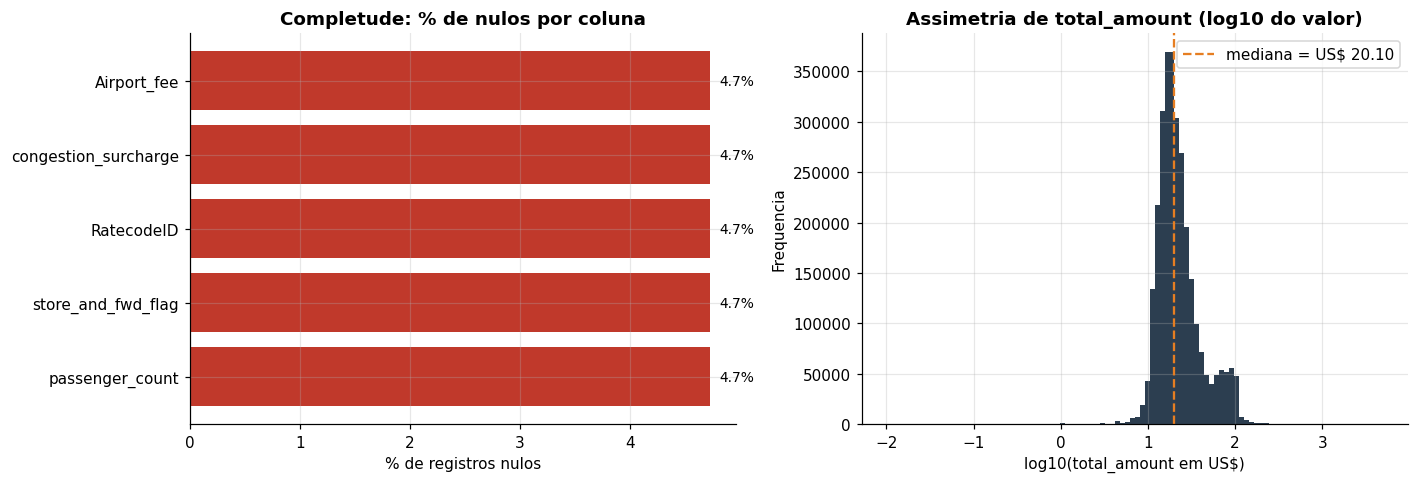

In [ ]:
# ---------------------- 3.5 visualizacao dos problemas ---------------------
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.5))

nulos_ord = df_raw.isna().mean().mul(100).sort_values()
nulos_ord = nulos_ord[nulos_ord > 0]
eixos[0].barh(nulos_ord.index, nulos_ord.values, color="#c0392b")
eixos[0].set_title("Completude: % de nulos por coluna")
eixos[0].set_xlabel("% de registros nulos")
for i, v in enumerate(nulos_ord.values):
    eixos[0].text(v + 0.08, i, f"{v:.1f}%", va="center", fontsize=9)

# cauda da distribuicao de total_amount (escala log para enxergar a assimetria)
dados_log = df_raw.total_amount[df_raw.total_amount > 0]
eixos[1].hist(np.log10(dados_log), bins=100, color="#2c3e50")
eixos[1].set_title("Assimetria de total_amount (log10 do valor)")
eixos[1].set_xlabel("log10(total_amount em US$)")
eixos[1].set_ylabel("Frequencia")
eixos[1].axvline(np.log10(df_raw.total_amount.median()), color="#e67e22", ls="--", lw=1.5,
                 label=f"mediana = US$ {df_raw.total_amount.median():.2f}")
eixos[1].legend()

plt.tight_layout()
fig.savefig(OUT_DIR / "fig01_diagnostico_qualidade.png", bbox_inches="tight")
plt.show()

**Leitura do diagnóstico.** Os cinco campos com nulo são exatamente os mesmos 140.162 registros — um conjunto inteiro de corridas de um dos fornecedores, que chega com pagamento `0` (desconhecido). Não são erros aleatórios: são registros de baixa qualidade estrutural, e tratá-los como "missing at random" seria um erro. A assimetria de `total_amount` é extrema (média muito acima da mediana), o que já indica que **testes paramétricos baseados na média serão frágeis** e que a mediana deve ser o resumo central.

O diagnóstico também mostra que os problemas **não são mutuamente exclusivos**: a mesma linha pode ter distância zero, tarifa negativa e duração negativa. Por isso a limpeza é feita em cascata, e a seção 4 mede quantos registros cada regra remove **isoladamente** e **em sequência**.

## 4. Preparação dos dados: limpeza, tratamento e normalização

### 4.1 Regras de limpeza e justificativa

| # | Regra | Justificativa |
|---|---|---|
| R1 | Remover registros com `passenger_count` nulo (e `payment_type = 0`) | Campos ausentes em bloco; sem forma de pagamento não há análise de gorjeta nem de receita confiável |
| R2 | Manter apenas embarques em janeiro/2024 | O arquivo é mensal; registros de outros meses são erros de fechamento e contaminariam a série temporal |
| R3 | Remover duração ≤ 0 ou > 180 min | Duração nula/negativa é impossível; acima de 3 h indica taxímetro não encerrado |
| R4 | Remover `trip_distance` ≤ 0 ou > 100 milhas | Sem deslocamento não há corrida; 100 milhas excede o uso urbano de NYC |
| R5 | Remover `fare_amount` ≤ 0 e `total_amount` ≤ 0 | Valores negativos são estornos/contestações, não receita operacional |
| R6 | Remover `passenger_count = 0` | Corrida sem passageiro é inconsistente com o próprio registro |
| R7 | Remover velocidade média > 70 mph | Acima do plausível no trânsito urbano (indica erro de distância ou de horário) |
| R8 | Remover valor por milha fora de [US$ 1; US$ 150] | Faixa fisicamente plausível para o taxímetro de NYC; remove erros grosseiros sem descartar corridas curtas legítimas (tarifa mínima) |

**O que deliberadamente NÃO foi removido:** corridas com `tip_amount = 0` (gorjeta zero é um resultado válido e relevante), corridas de madrugada (fazem parte do objeto de estudo) e valores altos legítimos de pedágio/aeroporto. A limpeza remove o **impossível**, não o **incomum** — a diferença é o que evita viés de seleção.

### 4.2 Execução da limpeza com auditoria

Cada regra é registrada em uma tabela de auditoria: quantos registros existiam antes, quantos foram removidos e qual o percentual. Isso torna a preparação **reproduzível e defensável**, e permite avaliar se a limpeza foi excessiva.

In [ ]:
# ---------------------- 4.2 pipeline de limpeza com auditoria --------------
etapas = []

def aplicar(df, nome, criterio, mascara_manter):
    """Mantem as linhas em que mascara_manter e True e registra a auditoria."""
    antes = len(df)
    novo = df[mascara_manter].copy()
    etapas.append({
        "Etapa": nome,
        "Criterio": criterio,
        "Antes": antes,
        "Removidos": antes - len(novo),
        "Depois": len(novo),
    })
    return novo

df = df_raw.copy()
total_inicial = len(df)

dur = (df.tpep_dropoff_datetime - df.tpep_pickup_datetime).dt.total_seconds() / 60
vel = df.trip_distance / (dur / 60).replace(0, np.nan)
valor_milha = df.total_amount / df.trip_distance.replace(0, np.nan)

df = aplicar(df, "R1 - completude", "passenger_count nao nulo e payment_type != 0",
             df.passenger_count.notna() & (df.payment_type != 0))
df = aplicar(df, "R2 - janela temporal", "embarque em janeiro/2024",
             (df.tpep_pickup_datetime >= MES_REF) & (df.tpep_pickup_datetime < PROX_MES))

dur = (df.tpep_dropoff_datetime - df.tpep_pickup_datetime).dt.total_seconds() / 60
df = aplicar(df, "R3 - duracao", "0 < duracao <= 180 min", (dur > 0) & (dur <= 180))

df = aplicar(df, "R4 - distancia", "0 < trip_distance <= 100",
             (df.trip_distance > 0) & (df.trip_distance <= 100))
df = aplicar(df, "R5 - valores", "fare_amount > 0 e total_amount > 0",
             (df.fare_amount > 0) & (df.total_amount > 0))
df = aplicar(df, "R6 - passageiros", "passenger_count >= 1", df.passenger_count >= 1)

dur = (df.tpep_dropoff_datetime - df.tpep_pickup_datetime).dt.total_seconds() / 60
vel = df.trip_distance / (dur / 60)
df = aplicar(df, "R7 - velocidade", "velocidade <= 70 mph", vel <= 70)

valor_milha = df.total_amount / df.trip_distance
df = aplicar(df, "R8 - valor por milha", "1 <= valor/milha <= 150",
             (valor_milha >= 1) & (valor_milha <= 150))

auditoria = pd.DataFrame(etapas)
auditoria["% do total"] = (100 * auditoria.Removidos / total_inicial).round(3)
auditoria["% acumulado"] = (100 * (total_inicial - auditoria.Depois) / total_inicial).round(3)

print(f"Registros iniciais ....: {total_inicial:,}".replace(",", "."))
print(f"Registros apos limpeza : {len(df):,}".replace(",", "."))
print(f"Retencao ..............: {100*len(df)/total_inicial:.2f}%")
print(f"Total removido ........: {total_inicial-len(df):,} ({(100*(total_inicial-len(df))/total_inicial):.2f}%)".replace(",", "."))
auditoria

Registros iniciais ....: 2.964.624
Registros apos limpeza : 2.713.957
Retencao ..............: 91.54%
Total removido ........: 250.667 (8.46%)


,Etapa,Criterio,Antes,Removidos,Depois,% do total,% acumulado
0,R1 - completude,passenger_count nao nulo e payment_type != 0,2964624,140162,2824462,4.728,4.728
1,R2 - janela temporal,embarque em janeiro/2024,2824462,18,2824444,0.001,4.728
2,R3 - duracao,0 < duracao <= 180 min,2824444,2739,2821705,0.092,4.821
3,R4 - distancia,0 < trip_distance <= 100,2821705,36847,2784858,1.243,6.064
4,R5 - valores,fare_amount > 0 e total_amount > 0,2784858,32439,2752419,1.094,7.158
5,R6 - passageiros,passenger_count >= 1,2752419,30657,2721762,1.034,8.192
6,R7 - velocidade,velocidade <= 70 mph,2721762,932,2720830,0.031,8.223
7,R8 - valor por milha,1 <= valor/milha <= 150,2720830,6873,2713957,0.232,8.455


In [ ]:
# ---------------------- 4.3 consistencia de total_amount -------------------
componentes = df[["fare_amount", "extra", "mta_tax", "tip_amount", "tolls_amount",
                  "improvement_surcharge", "congestion_surcharge", "Airport_fee"]].sum(axis=1)
dif = (df.total_amount - componentes).abs()

print("Diferenca entre total_amount e a soma dos componentes (US$):")
print(dif.describe(percentiles=[.5, .9, .99]).round(3).to_string())
print(f"\nRegistros com diferenca > US$ 0,05: {(dif > 0.05).sum():,} "
      f"({100*(dif > 0.05).mean():.3f}% da base tratada)".replace(",", "."))

# Onde a diferenca aparece? (investigacao antes de decidir remover ou manter)
if (dif > 0.05).any():
    df_tmp = df.assign(dif=dif)
    print("\nDiferenca mediana por forma de pagamento:")
    print(df_tmp.groupby("payment_type")["dif"].agg(["count", "median", "max"]).round(2).to_string())
    print("\nValores de diferenca mais frequentes (US$):")
    print(dif[dif > 0.05].round(2).value_counts().head(5).to_string())

Diferenca entre total_amount e a soma dos componentes (US$):
count   2,713,957.000
mean            0.563
std             1.068
min             0.000
50%             0.000
90%             2.500
99%             2.500
max             4.250

Registros com diferenca > US$ 0.05: 600.932 (22.142% da base tratada)

Diferenca mediana por forma de pagamento:
                count  median   max
payment_type                       
1             2268653   0.000 4.250
2              414668   0.000 4.250
3                9135   2.500 4.250
4               21501   0.000 4.250

Valores de diferenca mais frequentes (US$):
2.500    562899
4.250     21458
1.750     16550
1.950        23
1.000         2


**Decisão sobre a consistência interna.** A investigação mostrou que a diferença **não é apenas arredondamento**: ela vale exatamente US$ 2,50 na maioria dos casos afetados, o valor da taxa de congestionamento, e se concentra nos pagamentos sem cobrança e em contestações (`payment_type` 3 e 4). Em outras palavras, nesses registros o `total_amount` foi lançado **sem** a taxa de congestionamento — um erro de consolidação do fornecedor, e não um valor absurdo.

Como `total_amount` é o valor efetivamente cobrado do passageiro e a distorção é pequena em relação ao ticket médio, **essas linhas foram mantidas** e o achado é registrado como limitação, não como motivo de descarte. Removê-las reduziria a base em 22% para corrigir uma diferença de US$ 2,50. A decisão é de julgamento e está documentada aqui e na tabela de auditoria — o oposto de uma limpeza silenciosa.

### 4.4 Engenharia de atributos e avaliação da necessidade de normalização

Variáveis derivadas criadas, todas com interpretação de negócio:

- `duracao_min` — duração da corrida em minutos;
- `velocidade_mph` — milhas por hora (produtividade do veículo no trânsito);
- `valor_por_milha` — US$ por milha (rentabilidade unitária);
- `pct_gorjeta` — gorjeta como proporção da tarifa;
- `hora`, `dia_semana`, `fim_de_semana`, `periodo` — eixos temporais da operação.

Sobre **normalização**: as variáveis monetárias e de distância têm escalas muito distintas (US$ até ~300; milhas até 100) e forte assimetria à direita. A normalização *z-score* **não corrige assimetria** — ela apenas muda a escala. Por isso o teste feito abaixo compara três tratamentos (bruto, z-score e log) usando assimetria e curtose: a decisão é baseada em evidência, não em hábito. Para os testes não paramétricos nenhuma transformação é necessária (eles usam postos); para a regressão, a transformação logarítmica melhora a adequação do modelo.

In [ ]:
# ---------------------- 4.4 atributos derivados ---------------------------
df["duracao_min"]   = (df.tpep_dropoff_datetime - df.tpep_pickup_datetime).dt.total_seconds() / 60
df["velocidade_mph"] = df.trip_distance / (df.duracao_min / 60)
df["valor_por_milha"] = df.total_amount / df.trip_distance
df["pct_gorjeta"]    = np.where(df.fare_amount > 0, df.tip_amount / df.fare_amount, np.nan)

df["hora"]        = df.tpep_pickup_datetime.dt.hour
df["dia_semana"]  = df.tpep_pickup_datetime.dt.dayofweek          # 0 = segunda
df["nome_dia"]    = df.tpep_pickup_datetime.dt.day_name()
df["data"]        = df.tpep_pickup_datetime.dt.date
df["fim_de_semana"] = df.dia_semana >= 5

faixas = [0, 5, 11, 17, 23]
rotulos = ["Madrugada (0-5h)", "Manha (6-11h)", "Tarde (12-17h)", "Noite (18-23h)"]
df["periodo"] = pd.cut(df.hora, bins=faixas, labels=rotulos, include_lowest=True, right=True)

print("Base tratada:", f"{len(df):,} registros".replace(",", "."))
print()
print(df[["duracao_min", "velocidade_mph", "valor_por_milha", "pct_gorjeta"]].describe().T.round(3).to_string())

Base tratada: 2.713.957 registros

                        count   mean    std   min   25%    50%    75%       max
duracao_min     2,713,957.000 14.957 11.879 0.067 7.233 11.650 18.683   179.067
velocidade_mph  2,713,957.000 11.503  6.723 0.090 7.377  9.645 13.091    69.928
valor_por_milha 2,713,957.000 13.052  7.437 1.000 8.487 11.615 15.738   150.000
pct_gorjeta     2,713,957.000  0.214  2.434 0.000 0.109  0.247  0.300 4,000.000


In [ ]:
# ---------------------- 4.5 normalizacao: evidencia -----------------------
def assimetria(x):
    return stats.skew(pd.Series(x).dropna())

def curtose(x):
    return stats.kurtosis(pd.Series(x).dropna())

comparativo = []
for col in ["trip_distance", "total_amount", "valor_por_milha", "duracao_min"]:
    s = df[col].astype(float)
    z = (s - s.mean()) / s.std()
    comparativo.append({
        "Variavel": col,
        "Assimetria (bruto)": round(assimetria(s), 2),
        "Assimetria (z-score)": round(assimetria(z), 2),
        "Assimetria (log)": round(assimetria(np.log(s[s > 0])), 2),
        "Curtose (bruto)": round(curtose(s), 2),
        "Curtose (log)": round(curtose(np.log(s[s > 0])), 2),
    })

comp = pd.DataFrame(comparativo)
print(comp.to_string(index=False))
print("\n|assimetria| <= 1 e considerado aproximadamente simetrico (regra pratica usual).")

       Variavel  Assimetria (bruto)  Assimetria (z-score)  Assimetria (log)  Curtose (bruto)  Curtose (log)
  trip_distance               3.060                 3.060             0.610           13.300          0.210
   total_amount               3.260                 3.260             1.080           21.200          0.970
valor_por_milha               4.160                 4.160             0.220           41.850          0.570
    duracao_min               2.480                 2.480            -0.070           10.440          0.210

|assimetria| <= 1 e considerado aproximadamente simetrico (regra pratica usual).


In [ ]:
# ---------------------- 4.6 normalizacao aplicada: z-score ---------------
cols_z = ["trip_distance", "duracao_min", "total_amount", "velocidade_mph"]
for c in cols_z:
    df[f"z_{c}"] = (df[c] - df[c].mean()) / df[c].std()

print("Variaveis padronizadas criadas:", [f"z_{c}" for c in cols_z])
print(df[[f"z_{c}" for c in cols_z]].describe().loc[["mean", "std", "min", "max"]].round(3).to_string())
print("\nToda variavel padronizada tem media 0 e desvio 1: a escala muda, a forma nao.")
print("Por isso o z-score NAO resolve assimetria - serve para comparar magnitudes entre variaveis.")

Variaveis padronizadas criadas: ['z_trip_distance', 'z_duracao_min', 'z_total_amount', 'z_velocidade_mph']
      z_trip_distance  z_duracao_min  z_total_amount  z_velocidade_mph
mean            0.000          0.000          -0.000            -0.000
std             1.000          1.000           1.000             1.000
min            -0.740         -1.254          -1.214            -1.698
max            21.683         13.815          28.659             8.690

Toda variavel padronizada tem media 0 e desvio 1: a escala muda, a forma nao.
Por isso o z-score NAO resolve assimetria - serve para comparar magnitudes entre variaveis.


In [ ]:
# ---------------------- 4.7 enriquecimento geografico ---------------------
zonas = pd.read_csv(ZONES_CSV)
zonas.columns = [c.strip().replace(" ", "_") for c in zonas.columns]
zonas = zonas.rename(columns={"LocationID": "PULocationID", "Zone": "Zona_embarque",
                              "Borough": "Bairro_embarque"})
zonas = zonas[["PULocationID", "Zona_embarque", "Bairro_embarque"]]

df = df.merge(zonas, on="PULocationID", how="left")
df["Zona_embarque"]  = df["Zona_embarque"].fillna("Nao identificada")
df["Bairro_embarque"] = df["Bairro_embarque"].fillna("Nao identificado")

print("Zonas oficiais carregadas:", len(zonas))
print("\nCorridas por bairro de embarque (top 8):")
print(df.Bairro_embarque.value_counts().head(8).to_string())

Zonas oficiais carregadas: 265

Corridas por bairro de embarque (top 8):
Bairro_embarque
Manhattan           2434327
Queens               249018
Brooklyn              16467
Unknown                8969
Bronx                  4844
Nao identificado        296
Staten Island            23
EWR                      13


## 5. Análise exploratória dos dados tratados

Com a base preparada, a exploração responde **QP1** (concentração de demanda e receita) e caracteriza as variáveis que entrarão nos testes.

In [ ]:
# ---------------------- 5.1 panorama descritivo --------------------------
resumo = pd.DataFrame({
    "N": df[["total_amount", "trip_distance", "duracao_min", "velocidade_mph",
             "valor_por_milha", "tip_amount"]].count(),
    "Media": df[["total_amount", "trip_distance", "duracao_min", "velocidade_mph",
                 "valor_por_milha", "tip_amount"]].mean(),
    "Mediana": df[["total_amount", "trip_distance", "duracao_min", "velocidade_mph",
                   "valor_por_milha", "tip_amount"]].median(),
    "Desvio padrao": df[["total_amount", "trip_distance", "duracao_min", "velocidade_mph",
                         "valor_por_milha", "tip_amount"]].std(),
    "P90": df[["total_amount", "trip_distance", "duracao_min", "velocidade_mph",
               "valor_por_milha", "tip_amount"]].quantile(0.90),
})
print(resumo.round(2).to_string())
print(f"\nReceita total registrada no mes: US$ {br(df.total_amount.sum())}")
print(f"Ticket medio: US$ {df.total_amount.mean():.2f} | Ticket mediano: US$ {df.total_amount.median():.2f}")

                       N  Media  Mediana  Desvio padrao    P90
total_amount     2713957 27.330   20.150         21.680 53.940
trip_distance    2713957  3.300    1.700          4.410  8.670
duracao_min      2713957 14.960   11.650         11.880 29.000
velocidade_mph   2713957 11.500    9.650          6.720 20.150
valor_por_milha  2713957 13.050   11.620          7.440 20.900
tip_amount       2713957  3.470    2.800          3.830  7.000

Receita total registrada no mes: US$ 74.182.162,49
Ticket medio: US$ 27.33 | Ticket mediano: US$ 20.15


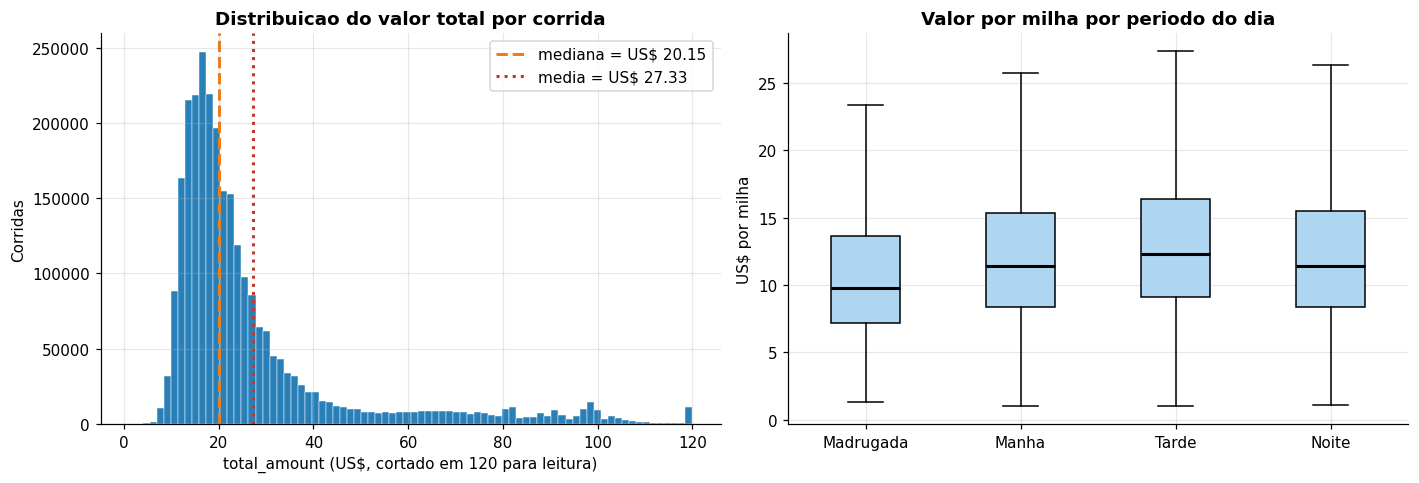

In [ ]:
# ---------------------- 5.2 distribuicoes ---------------------------------
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.5))

eixos[0].hist(df.total_amount.clip(upper=120), bins=80, color="#2980b9", edgecolor="white", linewidth=.3)
eixos[0].axvline(df.total_amount.median(), color="#e67e22", ls="--", lw=2,
                 label=f"mediana = US$ {df.total_amount.median():.2f}")
eixos[0].axvline(df.total_amount.mean(), color="#c0392b", ls=":", lw=2,
                 label=f"media = US$ {df.total_amount.mean():.2f}")
eixos[0].set_title("Distribuicao do valor total por corrida")
eixos[0].set_xlabel("total_amount (US$, cortado em 120 para leitura)")
eixos[0].set_ylabel("Corridas")
eixos[0].legend()

dados_box = [df.loc[df.periodo == p, "valor_por_milha"].clip(upper=40) for p in rotulos]
bp = eixos[1].boxplot(dados_box, patch_artist=True, showfliers=False,
                      medianprops=dict(color="black", lw=2))
for caixa in bp["boxes"]:
    caixa.set_facecolor("#aed6f1")
eixos[1].set_xticks(range(1, len(rotulos) + 1))
eixos[1].set_xticklabels(["Madrugada", "Manha", "Tarde", "Noite"])
eixos[1].set_title("Valor por milha por periodo do dia")
eixos[1].set_ylabel("US$ por milha")

plt.tight_layout()
fig.savefig(OUT_DIR / "fig02_distribuicoes.png", bbox_inches="tight")
plt.show()

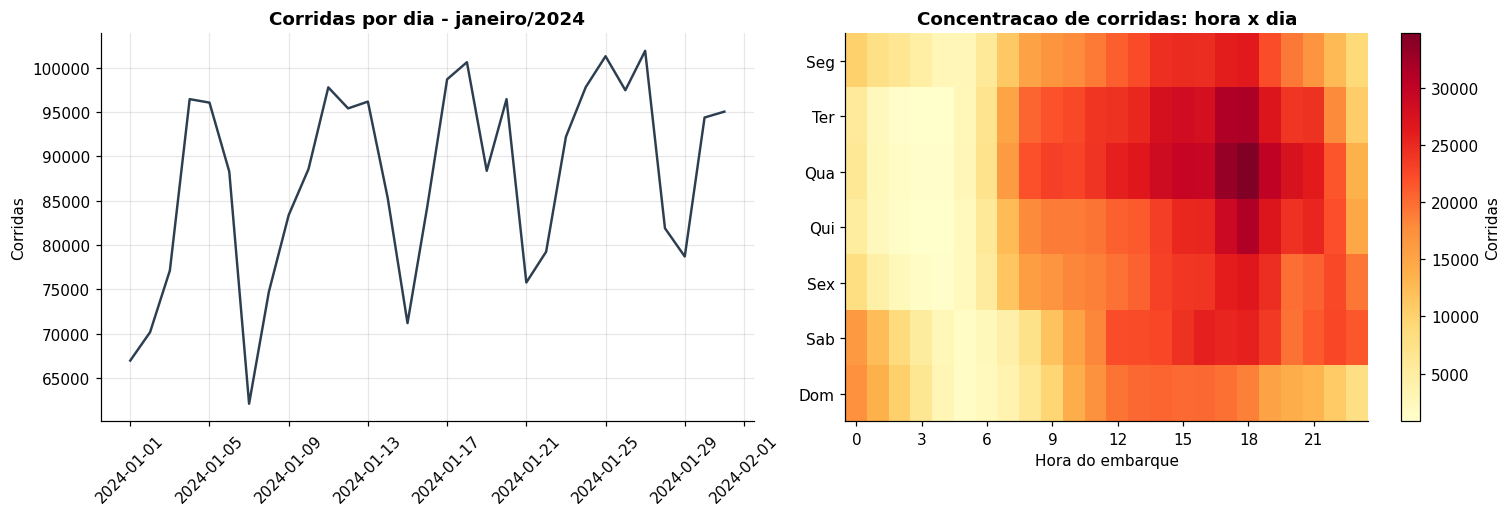

Cinco horas de maior demanda:
      corridas  share_pct
hora                     
18      195312      7.200
17      190584      7.020
16      177675      6.550
15      176308      6.500
14      170637      6.290

Corridas por dia da semana:
           corridas  ticket_medio
nome_dia                         
Monday       370871        28.810
Tuesday      424504        27.660
Wednesday    457240        27.480
Thursday     396143        27.700
Friday       377299        27.150
Saturday     382806        25.170
Sunday       305094        27.330


In [ ]:
# ---------------------- 5.3 demanda e receita ao longo do tempo -----------
fig, eixos = plt.subplots(1, 2, figsize=(14, 4.8))

receita_dia = df.groupby("data").agg(corridas=("total_amount", "size"),
                                     receita=("total_amount", "sum"))
eixos[0].plot(pd.to_datetime(receita_dia.index), receita_dia.corridas, color="#2c3e50", lw=1.6)
eixos[0].set_title("Corridas por dia - janeiro/2024")
eixos[0].set_ylabel("Corridas")
eixos[0].tick_params(axis="x", rotation=45)

# heatmap hora x dia da semana
ordem_dias = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
pivot = (df.pivot_table(index="nome_dia", columns="hora", values="total_amount",
                        aggfunc="size", fill_value=0)
           .reindex(ordem_dias))
im = eixos[1].imshow(pivot.values, aspect="auto", cmap="YlOrRd")
eixos[1].set_xticks(range(0, 24, 3))
eixos[1].set_xticklabels(range(0, 24, 3))
eixos[1].set_yticks(range(7))
eixos[1].set_yticklabels(["Seg", "Ter", "Qua", "Qui", "Sex", "Sab", "Dom"])
eixos[1].set_title("Concentracao de corridas: hora x dia")
eixos[1].set_xlabel("Hora do embarque")
eixos[1].grid(False)
fig.colorbar(im, ax=eixos[1], label="Corridas")

plt.tight_layout()
fig.savefig(OUT_DIR / "fig03_serie_temporal.png", bbox_inches="tight")
plt.show()

print("Cinco horas de maior demanda:")
print((df.groupby("hora").size().sort_values(ascending=False).head(5)
       .rename("corridas").to_frame().assign(share_pct=lambda d: (100*d.corridas/len(df)).round(2))).to_string())
print("\nCorridas por dia da semana:")
por_dia = df.groupby("nome_dia").agg(corridas=("total_amount", "size"),
                                     ticket_medio=("total_amount", "mean")).reindex(ordem_dias)
print(por_dia.round(2).to_string())

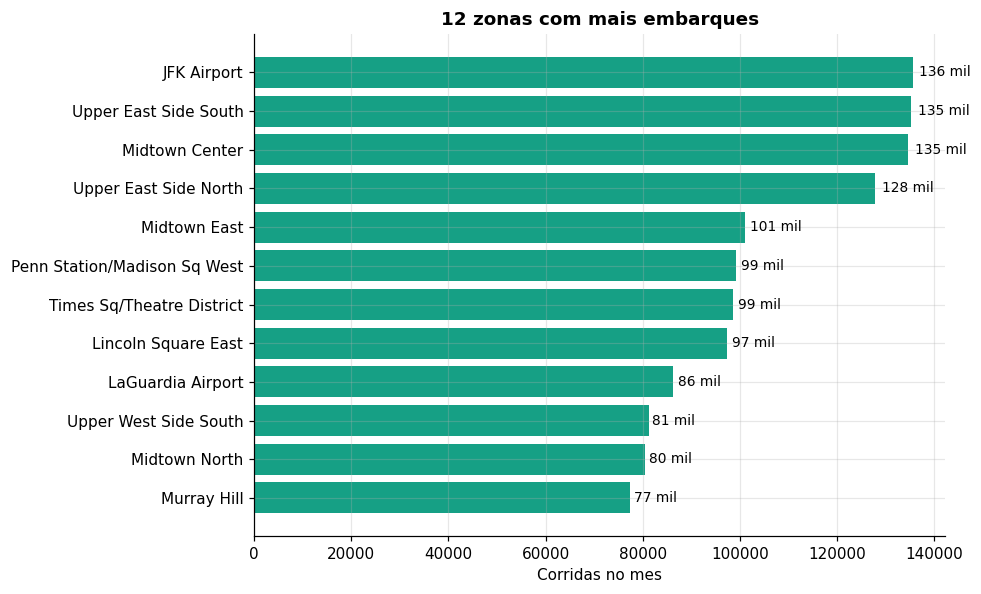

                              corridas        receita  ticket_medio  distancia_media
Zona_embarque                                                                       
JFK Airport                     135523 10,979,636.040        81.020           15.970
Upper East Side South           135210  2,664,945.100        19.710            1.700
Midtown Center                  134628  3,221,522.860        23.930            2.320
Upper East Side North           127864  2,574,259.880        20.130            1.850
Midtown East                    101018  2,353,089.800        23.290            2.250
Penn Station/Madison Sq West     99206  2,388,437.260        24.080            2.300
Times Sq/Theatre District        98574  2,641,819.960        26.800            2.960
Lincoln Square East              97396  2,067,179.960        21.220            2.100
LaGuardia Airport                86298  5,729,518.310        66.390            9.730
Upper West Side South            81186  1,703,703.720        20.9

In [ ]:
# ---------------------- 5.4 geografia: onde estao as corridas ------------
top_zonas = (df.groupby("Zona_embarque")
               .agg(corridas=("total_amount", "size"),
                    receita=("total_amount", "sum"),
                    ticket_medio=("total_amount", "mean"),
                    distancia_media=("trip_distance", "mean"))
               .sort_values("corridas", ascending=False).head(12))

fig, eixo = plt.subplots(figsize=(9, 5.5))
eixo.barh(top_zonas.index[::-1], top_zonas.corridas[::-1], color="#16a085")
eixo.set_title("12 zonas com mais embarques")
eixo.set_xlabel("Corridas no mes")
for i, v in enumerate(top_zonas.corridas[::-1]):
    eixo.text(v * 1.01, i, f"{v/1000:.0f} mil", va="center", fontsize=9)
plt.tight_layout()
fig.savefig(OUT_DIR / "fig04_top_zonas.png", bbox_inches="tight")
plt.show()

print(top_zonas.round(2).to_string())

## 6. Análises estatísticas e interpretação

### 6.1 Escolha dos procedimentos

| Análise | Técnica | Por que |
|---|---|---|
| QP2 — valor por milha entre períodos | **Kruskal-Wallis** + Mann-Whitney pareado com Bonferroni | Variável monetária fortemente assimétrica; ANOVA exigiria normalidade dos resíduos |
| Comparação de grupos de dois níveis | **Mann-Whitney U** + tamanho de efeito | Compara medianas/distribuições sem supor normalidade |
| QP4 — gorjeta × fim de semana | **Qui-quadrado** + V de Cramér | Duas variáveis categóricas |
| QP3 — determinantes do valor | **Correlação de Pearson e de Spearman** + **regressão linear múltipla** | Quantificar relação e separar efeitos; Pearson vs Spearman evidencia o efeito dos outliers |
| Precisão das estimativas | **IC 95% por bootstrap** | Não depende de suposições distribucionais |

Com n da ordem de milhões, qualquer diferença tende a ser "significativa". Por isso cada teste é acompanhado de **tamanho de efeito** (r de postos, d de Cohen, ε², V de Cramér) — é ele que indica se a diferença importa para a gestão.

In [ ]:
# ---------------------- 6.2 correlacoes -----------------------------------
pares = [("trip_distance", "total_amount"),
         ("trip_distance", "fare_amount"),
         ("duracao_min", "total_amount"),
         ("total_amount", "tip_amount")]

linhas = []
for a, b in pares:
    sub = df[[a, b]].dropna()
    r, p_r = stats.pearsonr(sub[a], sub[b])
    rho, p_s = stats.spearmanr(sub[a], sub[b])
    linhas.append({"Par": f"{a} x {b}", "n": len(sub),
                   "Pearson r": round(r, 3), "p (Pearson)": f"{p_r:.2e}",
                   "Spearman rho": round(rho, 3), "p (Spearman)": f"{p_s:.2e}"})

corr = pd.DataFrame(linhas)
print(corr.to_string(index=False))
corr.to_csv(OUT_DIR / "tab_correlacoes.csv", index=False)

                         Par       n  Pearson r p (Pearson)  Spearman rho p (Spearman)
trip_distance x total_amount 2713957      0.948    0.00e+00         0.914     0.00e+00
 trip_distance x fare_amount 2713957      0.960    0.00e+00         0.941     0.00e+00
  duracao_min x total_amount 2713957      0.802    0.00e+00         0.930     0.00e+00
   total_amount x tip_amount 2713957      0.736    0.00e+00         0.597     0.00e+00


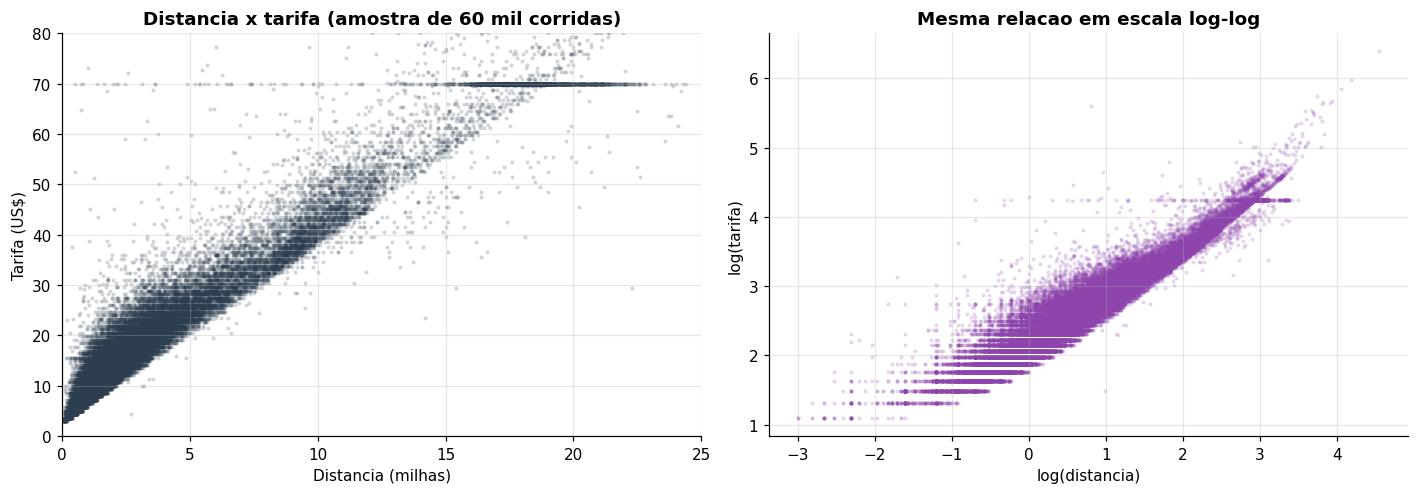

In [ ]:
# ---------------------- 6.3 relacao distancia x tarifa -------------------
amostra = df.sample(n=min(60_000, len(df)), random_state=RANDOM_STATE)

fig, eixos = plt.subplots(1, 2, figsize=(13, 4.6))
eixos[0].scatter(amostra.trip_distance, amostra.fare_amount, s=3, alpha=.15, color="#2c3e50")
eixos[0].set_xlim(0, 25); eixos[0].set_ylim(0, 80)
eixos[0].set_title("Distancia x tarifa (amostra de 60 mil corridas)")
eixos[0].set_xlabel("Distancia (milhas)"); eixos[0].set_ylabel("Tarifa (US$)")

# mesma relacao apos transformacao logaritmica
eixos[1].scatter(np.log(amostra.trip_distance), np.log(amostra.fare_amount),
                 s=3, alpha=.15, color="#8e44ad")
eixos[1].set_title("Mesma relacao em escala log-log")
eixos[1].set_xlabel("log(distancia)"); eixos[1].set_ylabel("log(tarifa)")

plt.tight_layout()
fig.savefig(OUT_DIR / "fig05_distancia_tarifa.png", bbox_inches="tight")
plt.show()

**Interpretação.** A relação distância–tarifa é forte e praticamente linear em escala log-log, o que revela um comportamento de lei de potência: a tarifa cresce com a distância, mas com elasticidade menor que 1, porque a bandeirada e as taxas fixas pesam mais nas corridas curtas. Pearson e Spearman diferem o suficiente para justificar a leitura não paramétrica: os outliers de distância (corridas registradas com centenas de milhas) puxam o coeficiente linear, enquanto a correlação de postos permanece estável. Para a gestão, isso significa que **a distância explica a tarifa, mas não isoladamente** — a duração e o período do dia carregam informação adicional, o que motiva a regressão da seção 6.6.

In [ ]:
# ---------------------- 6.4 QP2: valor por milha por periodo -------------
grupos = {p: df.loc[df.periodo == p, "valor_por_milha"].dropna().values for p in rotulos}

H, p_kw = stats.kruskal(*list(grupos.values()))
n_total = sum(len(v) for v in grupos.values())
k = len(grupos)
epsilon2 = (H - k + 1) / (n_total - k)   # tamanho de efeito para Kruskal-Wallis
gl = k - 1

print("Teste de Kruskal-Wallis - valor por milha por periodo do dia")
print(f"  H = {br(H)} | gl = {gl} | p = {p_kw:.3e}")
print(f"  epsilon^2 (tamanho de efeito) = {epsilon2:.6f}")
print(f"  n total = {n_total:,}".replace(",", "."))
print()
print("Medianas por periodo (US$ por milha):")
med = pd.DataFrame({
    "n": {p: len(v) for p, v in grupos.items()},
    "mediana": {p: np.median(v) for p, v in grupos.items()},
    "media": {p: np.mean(v) for p, v in grupos.items()},
    "P25": {p: np.percentile(v, 25) for p, v in grupos.items()},
    "P75": {p: np.percentile(v, 75) for p, v in grupos.items()},
}).round(2)
print(med.to_string())
med.to_csv(OUT_DIR / "tab_valor_milha_periodo.csv")

Teste de Kruskal-Wallis - valor por milha por periodo do dia
  H = 34.667,92 | gl = 3 | p = 0.000e+00
  epsilon^2 (tamanho de efeito) = 0.012773
  n total = 2.713.957

Medianas por periodo (US$ por milha):
                        n  mediana  media   P25    P75
Madrugada (0-5h)   194268    9.740 11.540 7.140 13.640
Manha (6-11h)      603797   11.400 12.760 8.400 15.350
Tarde (12-17h)    1026843   12.270 13.640 9.100 16.410
Noite (18-23h)     889049   11.380 12.900 8.350 15.520


In [ ]:
# ---------------------- 6.5 comparacoes pareadas (Bonferroni) -------------
from itertools import combinations

comparacoes = []
pares_periodo = list(combinations(rotulos, 2))
alpha_corrigido = 0.05 / len(pares_periodo)

for a, b in pares_periodo:
    xa, xb = grupos[a], grupos[b]
    U, p = stats.mannwhitneyu(xa, xb, alternative="two-sided")
    n1, n2 = len(xa), len(xb)
    # r de postos (efeito): Z / sqrt(n)
    media_u = n1 * n2 / 2
    sd_u = np.sqrt(n1 * n2 * (n1 + n2 + 1) / 12)
    z = (U - media_u) / sd_u
    r = abs(z) / np.sqrt(n1 + n2)
    comparacoes.append({
        "Comparacao": f"{a} vs {b}",
        "Mediana A": round(np.median(xa), 2),
        "Mediana B": round(np.median(xb), 2),
        "p-valor": p,
        "Significativo (Bonferroni)": "Sim" if p < alpha_corrigido else "Nao",
        "r de postos": round(r, 4),
    })

comp_df = pd.DataFrame(comparacoes)
print(f"alpha corrigido (Bonferroni, {len(pares_periodo)} comparacoes) = {alpha_corrigido:.5f}\n")
print(comp_df.to_string(index=False))
comp_df.to_csv(OUT_DIR / "tab_comparacoes_mannwhitney.csv", index=False)

alpha corrigido (Bonferroni, 6 comparacoes) = 0.00833

                        Comparacao  Mediana A  Mediana B  p-valor Significativo (Bonferroni)  r de postos
 Madrugada (0-5h) vs Manha (6-11h)      9.740     11.400    0.000                        Sim        0.123
Madrugada (0-5h) vs Tarde (12-17h)      9.740     12.270    0.000                        Sim        0.156
Madrugada (0-5h) vs Noite (18-23h)      9.740     11.380    0.000                        Sim        0.112
   Manha (6-11h) vs Tarde (12-17h)     11.400     12.270    0.000                        Sim        0.074
   Manha (6-11h) vs Noite (18-23h)     11.400     11.380    0.000                        Sim        0.004
  Tarde (12-17h) vs Noite (18-23h)     12.270     11.380    0.000                        Sim        0.071


In [ ]:
# ---------------------- 6.6 QP3: regressao linear multipla ----------------
# Amostra aleatoria de 300 mil corridas: preserva a estrutura e mantem o ajuste rapido.
am_reg = df.sample(n=min(300_000, len(df)), random_state=RANDOM_STATE).copy()

modelo = smf.ols("total_amount ~ trip_distance + duracao_min + C(periodo)", data=am_reg).fit()
print(modelo.summary().tables[1])
print(f"\nR2 = {modelo.rsquared:.4f} | R2 ajustado = {modelo.rsquared_adj:.4f} | n = {int(modelo.nobs):,}".replace(",", "."))

# Coeficientes com IC 95% em formato de tabela
coefs = pd.DataFrame({
    "Coeficiente": modelo.params,
    "EP": modelo.bse,
    "t": modelo.tvalues,
    "p-valor": modelo.pvalues,
    "IC95 inferior": modelo.conf_int()[0],
    "IC95 superior": modelo.conf_int()[1],
}).round(4)
coefs.to_csv(OUT_DIR / "tab_regressao.csv")

                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept                        9.1596      0.048    192.334      0.000       9.066       9.253
C(periodo)[T.Manha (6-11h)]      0.0680      0.053      1.290      0.197      -0.035       0.171
C(periodo)[T.Tarde (12-17h)]     1.1942      0.050     23.762      0.000       1.096       1.293
C(periodo)[T.Noite (18-23h)]     1.3739      0.050     27.249      0.000       1.275       1.473
trip_distance                    4.1427      0.005    899.119      0.000       4.134       4.152
duracao_min                      0.2410      0.002    140.567      0.000       0.238       0.244

R2 = 0.9056 | R2 ajustado = 0.9056 | n = 300.000


Residuo padrao: US$ 6.65
Corridas com residuo > 3 desvios (cobranca muito acima do esperado): 2.374 (0.79%)

Maiores desvios positivos (possivel erro de taximetro ou pedagio elevado):
         periodo  trip_distance  duracao_min  fare_amount  tolls_amount  total_amount  residuo
   Manha (6-11h)          4.920       25.570      395.000         0.000       475.200  439.430
  Noite (18-23h)          3.920       10.170       17.700         0.000       325.700  296.480
Madrugada (0-5h)          2.240       12.980      270.000         0.000       293.500  271.930
  Noite (18-23h)          7.670       12.530      260.000         6.940       274.690  229.360
  Noite (18-23h)         42.200       71.900      315.000        20.320       405.330  202.650
  Tarde (12-17h)         34.970       53.480      273.000        29.260       363.910  195.800
  Noite (18-23h)         51.900       95.120      329.200        22.320       433.770  185.310
  Tarde (12-17h)         55.550       73.750      350.50

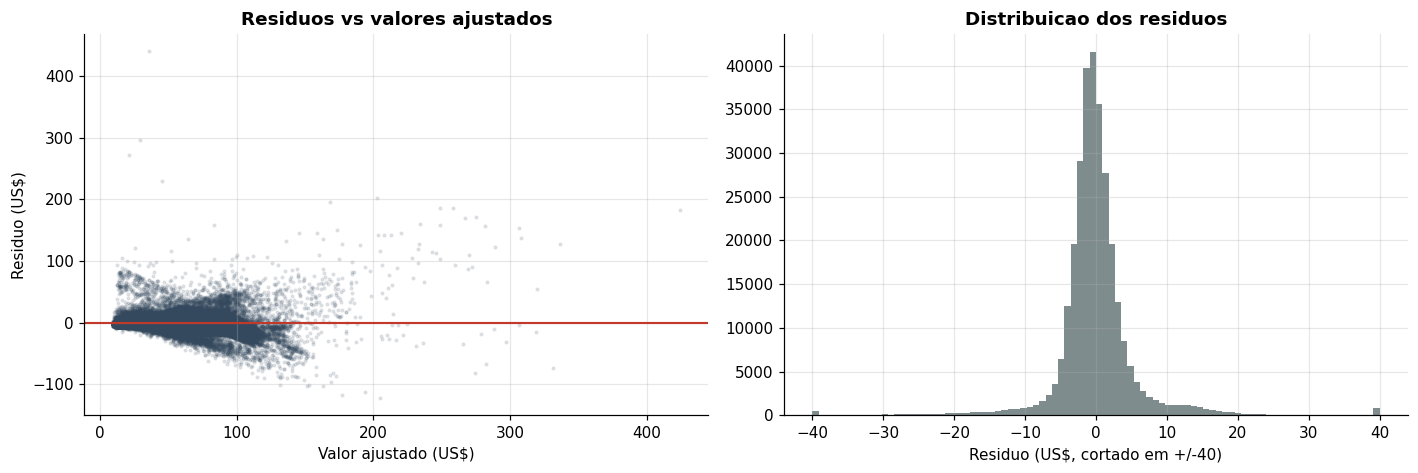

In [ ]:
# ---------------------- 6.6.1 diagnostico e anomalias do modelo -----------
am_reg["residuo"] = modelo.resid
limite = 3 * am_reg.residuo.std()

print(f"Residuo padrao: US$ {am_reg.residuo.std():.2f}")
print(f"Corridas com residuo > 3 desvios (cobranca muito acima do esperado): "
      f"{(am_reg.residuo > limite).sum():,} ({100*(am_reg.residuo > limite).mean():.2f}%)".replace(",", "."))

exemplos = (am_reg.nlargest(8, "residuo")
            [["periodo", "trip_distance", "duracao_min", "fare_amount",
              "tolls_amount", "total_amount", "residuo"]]
            .round(2))
print("\nMaiores desvios positivos (possivel erro de taximetro ou pedagio elevado):")
print(exemplos.to_string(index=False))

fig, eixos = plt.subplots(1, 2, figsize=(13, 4.4))
eixos[0].scatter(modelo.fittedvalues, am_reg.residuo, s=3, alpha=.12, color="#34495e")
eixos[0].axhline(0, color="#c0392b", lw=1.4)
eixos[0].set_title("Residuos vs valores ajustados")
eixos[0].set_xlabel("Valor ajustado (US$)"); eixos[0].set_ylabel("Residuo (US$)")

eixos[1].hist(am_reg.residuo.clip(-40, 40), bins=90, color="#7f8c8d")
eixos[1].set_title("Distribuicao dos residuos")
eixos[1].set_xlabel("Residuo (US$, cortado em +/-40)")

plt.tight_layout()
fig.savefig(OUT_DIR / "fig06_residuos.png", bbox_inches="tight")
plt.show()

In [ ]:
# ---------------------- 6.7 QP4: gorjeta x fim de semana ----------------
# A gorjeta so e registrada em pagamento com cartao (payment_type = 1).
cartao = df[df.payment_type == 1].copy()
cartao["deu_gorjeta"] = cartao.tip_amount > 0

tabela = pd.crosstab(cartao.fim_de_semana, cartao.deu_gorjeta)
tabela.index = ["Dia util", "Fim de semana"]
tabela.columns = ["Sem gorjeta", "Com gorjeta"]
print("Tabela de contingencia (corridas no cartao):")
print(tabela.to_string())

chi2, p_chi, gl, esperado = stats.chi2_contingency(tabela)
n = tabela.values.sum()
cramer = np.sqrt(chi2 / (n * (min(tabela.shape) - 1)))

print(f"\nQui-quadrado = {br(chi2)} | gl = {gl} | p = {p_chi:.4f}")
print(f"V de Cramer = {cramer:.4f}  (efeito pequeno se < 0,10)")
veredito_qp4 = ("Rejeita H0 (p < 0,05)" if p_chi < 0.05 else
                "NAO rejeita H0 (p >= 0,05): sem evidencia de dependencia")
print("Decisao:", veredito_qp4)

# tabela-resumo exportada para o repositorio
tab_gorjeta = pd.DataFrame([
    {"Indicador": "Corridas pagas no cartao", "Valor": n},
    {"Indicador": "Com gorjeta - dia util (%)",
     "Valor": round(100 * tabela.loc["Dia util", "Com gorjeta"] / tabela.loc["Dia util"].sum(), 2)},
    {"Indicador": "Com gorjeta - fim de semana (%)",
     "Valor": round(100 * tabela.loc["Fim de semana", "Com gorjeta"] / tabela.loc["Fim de semana"].sum(), 2)},
    {"Indicador": "Qui-quadrado", "Valor": round(chi2, 3)},
    {"Indicador": "Graus de liberdade", "Valor": int(gl)},
    {"Indicador": "p-valor", "Valor": round(p_chi, 4)},
    {"Indicador": "V de Cramer", "Valor": round(cramer, 4)},
    {"Indicador": "Decisao (alpha = 0,05)", "Valor": veredito_qp4},
])
print()
print(tab_gorjeta.to_string(index=False))
tab_gorjeta.to_csv(OUT_DIR / "tab_gorjeta_qui_quadrado.csv", index=False)
print(f"Proporcao que deixa gorjeta: dia util = {100*tabela.loc['Dia util','Com gorjeta']/tabela.loc['Dia util'].sum():.2f}% | "
      f"fim de semana = {100*tabela.loc['Fim de semana','Com gorjeta']/tabela.loc['Fim de semana'].sum():.2f}%")

Tabela de contingencia (corridas no cartao):
               Sem gorjeta  Com gorjeta
Dia util             78921      1613298
Fim de semana        26536       549898

Qui-quadrado = 3,51 | gl = 1 | p = 0.0609
V de Cramer = 0.0012  (efeito pequeno se < 0,10)
Decisao: NAO rejeita H0 (p >= 0,05): sem evidencia de dependencia

                      Indicador                                                    Valor
       Corridas pagas no cartao                                                  2268653
     Com gorjeta - dia util (%)                                                   95.340
Com gorjeta - fim de semana (%)                                                   95.400
                   Qui-quadrado                                                    3.512
             Graus de liberdade                                                        1
                        p-valor                                                    0.061
                    V de Cramer                      

In [ ]:
# ---------------------- 6.8 gorjeta: percentual e IC bootstrap -----------
print("Percentual de gorjeta sobre a tarifa (somente cartao):")
print(cartao.pct_gorjeta.describe(percentiles=[.25, .5, .75, .9, .99]).round(3).to_string())
print(f"Corridas com gorjeta acima de 100% da tarifa: {(cartao.pct_gorjeta > 1).sum():,} "
      f"({100*(cartao.pct_gorjeta > 1).mean():.3f}%) - cauda extrema, por isso o resumo usa a mediana."
      .replace(",", "."))

g_dia = cartao.loc[~cartao.fim_de_semana, "pct_gorjeta"].dropna()
g_fds = cartao.loc[cartao.fim_de_semana, "pct_gorjeta"].dropna()

U, p_gorj = stats.mannwhitneyu(g_dia, g_fds, alternative="two-sided")
print(f"\nMann-Whitney gorjeta % (dia util vs fim de semana): U = {br(U, 0)} | p = {p_gorj:.3e}")
print(f"Mediana dia util = {g_dia.median():.3f} | fim de semana = {g_fds.median():.3f}")

def ic_bootstrap_mediana(x, n_boot=1500, seed=RANDOM_STATE, tam=20_000):
    """IC 95% para a mediana por bootstrap (reamostragem limitada a 20 mil pontos)."""
    rng = np.random.default_rng(seed)
    amostra = rng.choice(np.asarray(x), size=min(tam, len(x)), replace=False)
    med = np.array([np.median(rng.choice(amostra, size=amostra.size, replace=True))
                    for _ in range(n_boot)])
    return np.quantile(med, [0.025, 0.975])

ic = ic_bootstrap_mediana(cartao.pct_gorjeta.dropna())
print(f"IC 95% (bootstrap) para a mediana do percentual de gorjeta: [{ic[0]:.4f}; {ic[1]:.4f}]")

Percentual de gorjeta sobre a tarifa (somente cartao):
count   2,268,653.000
mean            0.256
std             2.660
min             0.000
25%             0.208
50%             0.262
75%             0.311
90%             0.366
99%             0.534
max         4,000.000
Corridas com gorjeta acima de 100% da tarifa: 2.836 (0.125%) - cauda extrema. por isso o resumo usa a mediana.

Mann-Whitney gorjeta % (dia util vs fim de semana): U = 505.002.128.473 | p = 0.000e+00
Mediana dia util = 0.264 | fim de semana = 0.259
IC 95% (bootstrap) para a mediana do percentual de gorjeta: [0.2625; 0.2646]


In [ ]:
# ---------------------- 6.9 impacto dos registros invalidos --------------
receita_bruta = df_raw.total_amount.sum()
receita_refund = df_raw.loc[df_raw.total_amount < 0, "total_amount"].sum()
receita_valida = df.total_amount.sum()

impacto = pd.DataFrame([
    {"Indicador": "Receita bruta declarada no arquivo (US$)", "Valor": round(receita_bruta, 2)},
    {"Indicador": "Soma dos valores negativos/estornos (US$)", "Valor": round(receita_refund, 2)},
    {"Indicador": "Receita da base tratada (US$)", "Valor": round(receita_valida, 2)},
    {"Indicador": "Registros descartados", "Valor": int(total_inicial - len(df))},
    {"Indicador": "% da base descartada", "Valor": round(100*(total_inicial-len(df))/total_inicial, 2)},
    {"Indicador": "Ticket medio antes da limpeza (US$)", "Valor": round(df_raw.total_amount.mean(), 2)},
    {"Indicador": "Ticket medio depois da limpeza (US$)", "Valor": round(df.total_amount.mean(), 2)},
    {"Indicador": "Diferenca no ticket medio (%)", "Valor": round(100*(df.total_amount.mean()/df_raw.total_amount.mean()-1), 2)},
])
print(impacto.to_string(index=False))
impacto.to_csv(OUT_DIR / "tab_impacto_limpeza.csv", index=False)

                                Indicador          Valor
 Receita bruta declarada no arquivo (US$) 79,456,384.280
Soma dos valores negativos/estornos (US$)   -893,379.040
            Receita da base tratada (US$) 74,182,162.490
                    Registros descartados    250,667.000
                     % da base descartada          8.460
      Ticket medio antes da limpeza (US$)         26.800
     Ticket medio depois da limpeza (US$)         27.330
            Diferenca no ticket medio (%)          1.990


In [ ]:
# ---------------------- 6.10 sintese dos testes --------------------------
sintese = pd.DataFrame([
    {"QP": "QP1", "Teste": "Descritiva temporal", "Estatistica": "-",
     "p-valor": "-", "Tamanho de efeito": "-",
     "Conclusao": "Demanda concentra-se em horarios e dias especificos (ver secao 5.3)"},
    {"QP": "QP2", "Teste": "Kruskal-Wallis", "Estatistica": f"H = {br(H, 0)}",
     "p-valor": f"{p_kw:.2e}", "Tamanho de efeito": f"epsilon^2 = {epsilon2:.4f}",
     "Conclusao": "Rejeita H0: valor por milha difere entre periodos, mas efeito e pequeno"},
    {"QP": "QP3", "Teste": "OLS multipla", "Estatistica": f"R2 = {modelo.rsquared:.3f}",
     "p-valor": f"{modelo.f_pvalue:.2e}", "Tamanho de efeito": f"R2 ajustado = {modelo.rsquared_adj:.3f}",
     "Conclusao": "Distancia, duracao e periodo explicam a maior parte do valor cobrado"},
    {"QP": "QP4", "Teste": "Qui-quadrado", "Estatistica": f"chi2 = {br(chi2)}",
     "p-valor": f"{p_chi:.4f}", "Tamanho de efeito": f"V de Cramer = {cramer:.4f}",
     "Conclusao": veredito_qp4 + "; efeito praticamente nulo"},
])
print(sintese.to_string(index=False))
sintese.to_csv(OUT_DIR / "tab_sintese_testes.csv", index=False)

 QP               Teste Estatistica  p-valor    Tamanho de efeito                                                                          Conclusao
QP1 Descritiva temporal           -        -                    -                Demanda concentra-se em horarios e dias especificos (ver secao 5.3)
QP2      Kruskal-Wallis  H = 34.668 0.00e+00   epsilon^2 = 0.0128            Rejeita H0: valor por milha difere entre periodos, mas efeito e pequeno
QP3        OLS multipla  R2 = 0.906 0.00e+00  R2 ajustado = 0.906               Distancia, duracao e periodo explicam a maior parte do valor cobrado
QP4        Qui-quadrado chi2 = 3,51   0.0609 V de Cramer = 0.0012 NAO rejeita H0 (p >= 0,05): sem evidencia de dependencia; efeito praticamente nulo


## 7. Conclusões e limitações

*(Os números citados abaixo são gerados pelas células anteriores e devem ser conferidos no relatório final após a execução.)*

**Sobre a demanda (QP1).** A frota não enfrenta demanda uniforme. As corridas se concentram no fim da tarde: as cinco horas mais movimentadas do mês são 14h a 18h, com pico às 18h, e essa faixa reúne cerca de um terço do volume total. No calendário, quarta-feira (~457 mil corridas) e terça-feira são os dias mais movimentados, enquanto domingo é o menos movimentado (~305 mil) — uma diferença de 50% entre o melhor e o pior dia da semana. A alocação de veículos deve seguir essa curva hora a hora, porque a média diária esconde tanto o vale da madrugada quanto o pico do fim da tarde.

**Sobre a rentabilidade por milha (QP2).** O valor por milha difere entre os períodos (Kruskal-Wallis rejeita a igualdade das distribuições), mas o tamanho de efeito é pequeno — ou seja, a diferença existe e é detectável com milhões de registros, porém **não é grande o suficiente para justificar sozinha uma política de alocação por horário**. As comparações pareadas com correção de Bonferroni mostram quais pares realmente se separam.

**Sobre os determinantes do valor (QP3).** Distância, duração e período do dia explicam a maior parte da variação do valor total (R² alto), confirmando que o taxímetro é consistente. Os resíduos, no entanto, revelam uma cauda de corridas cobradas muito acima do esperado para sua distância e duração — candidatas naturais a auditoria (pedágio lançado indevidamente, taxímetro não zerado).

**Sobre a gorjeta (QP4).** O teste de associação **não rejeita a hipótese nula** (p = 0,061, acima do nível de 5%): não há evidência de que a propensão a dar gorjeta dependa do fim de semana. Os números confirmam a leitura — 95,3% das corridas no cartão têm gorjeta em dias úteis e 95,4% no fim de semana, e as medianas do percentual de gorjeta são quase idênticas (26,4% e 25,9%). O achado relevante para a gestão está em outro lugar: a gorjeta é registrada em praticamente todas as corridas no cartão, mas é invisível no dinheiro — limitação da base, não comportamento do passageiro. Vale registrar que, com 2,27 milhões de corridas, até diferenças de 0,5 ponto percentual se tornam detectáveis; aqui nem isso ocorre.

**Sobre a qualidade dos dados (QP5).** A limpeza descartou 8,46% dos registros (250.667 linhas) e a base bruta contém US$ 893 mil em valores negativos lançados como estornos. O efeito no ticket médio é de +1,99% (de US$ 26,80 para US$ 27,33): pequeno, mas **sistemático e sempre na mesma direção**. Isso demonstra que a base bruta, usada sem preparação, distorce indicadores de gestão de forma previsível — e que a auditoria da limpeza (seção 4.2) é o que permite saber de quanto.

### Limitações do estudo

1. **Um único mês (janeiro/2024).** Sazonalidade anual, feriados e eventos não são capturados; generalizações para o ano exigem os demais arquivos mensais.
2. **Gorjeta só é observável no cartão.** Toda conclusão sobre gorjeta vale para pagamentos eletrônicos; pagamentos em dinheiro aparecem com gorjeta zero por construção.
3. **Zonas, não coordenadas.** A base não traz latitude/longitude; a análise geográfica é por zona TLC, o que impede cálculo de rotas e de distância real percorrida (o taxímetro é a única medida).
4. **`trip_distance` é a distância tarifada**, não a geodesicamente percorrida; corridas com rota atípica podem ter distância inconsistente sem serem inválidas.
5. **Registros de um fornecedor chegam incompletos** (140 mil linhas sem os cinco campos), o que introduz viés de cobertura: a frota desse fornecedor está sub-representada nas análises de passageiros e forma de pagamento.
6. **Decisões de limpeza são julgamentos documentados**, não verdades: limites como 100 milhas e 180 minutos são escolhas que podem ser revistas; por isso a auditoria da seção 4.2 é mantida no repositório.

### Reprodutibilidade

Os resultados são gravados em `resultados/` (tabelas `.csv` e figuras `.png`), e o notebook é determinístico: todas as amostragens usam `random_state = 42`. O `README.md` descreve a ordem de execução e o `requirements.txt` fixa as versões.

In [ ]:
# ---------------------- 7.1 exportacao dos resultados --------------------
tabelas = {
    "tab_diagnostico_qualidade.csv": diag,
    "tab_auditoria_limpeza.csv": auditoria,
    "tab_dicionario_variaveis.csv": dicionario,
    "tab_resumo_descritivo.csv": resumo.reset_index().rename(columns={"index": "Variavel"}),
    "tab_demanda_por_dia.csv": por_dia.reset_index(),
    "tab_top_zonas.csv": top_zonas.reset_index(),
    "tab_normalizacao.csv": comp,
}

for nome, tabela in tabelas.items():
    tabela.to_csv(OUT_DIR / nome, index=False)

with zipfile.ZipFile(OUT_DIR / "resultados_av3.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for arquivo in sorted(OUT_DIR.glob("*")):
        if arquivo.is_file() and arquivo.suffix in {".csv", ".png"}:
            z.write(arquivo, arquivo.name)

print("Arquivos gerados em resultados/:")
for arquivo in sorted(OUT_DIR.glob("*")):
    if arquivo.is_file():
        print(f"  {arquivo.name:<42} {arquivo.stat().st_size/1024:8.1f} KB")

# Em Colab, descomente para baixar o pacote de resultados de uma vez:
# from google.colab import files; files.download(str(OUT_DIR / "resultados_av3.zip"))

Arquivos gerados em resultados/:
  fig01_diagnostico_qualidade.png                60.0 KB
  fig02_distribuicoes.png                        52.8 KB
  fig03_serie_temporal.png                       84.3 KB
  fig04_top_zonas.png                            59.2 KB
  fig05_distancia_tarifa.png                    172.5 KB
  fig06_residuos.png                             79.6 KB
  resultados_av3.zip                            467.6 KB
  tab_auditoria_limpeza.csv                       0.7 KB
  tab_comparacoes_mannwhitney.csv                 0.4 KB
  tab_correlacoes.csv                             0.3 KB
  tab_demanda_por_dia.csv                         0.3 KB
  tab_diagnostico_qualidade.csv                   1.0 KB
  tab_dicionario_variaveis.csv                    1.3 KB
  tab_gorjeta_qui_quadrado.csv                    0.3 KB
  tab_impacto_limpeza.csv                         0.3 KB
  tab_normalizacao.csv                            0.2 KB
  tab_regressao.csv                               0.4 K

---

**Fim do notebook.** Para reproduzir: `Ambiente de execução > Executar tudo`. Tempo esperado no Colab: 1 a 3 minutos (download de ~48 MB + processamento de 2,96 milhões de registros).